In [103]:
import numpy as np

import ufl

import dolfinx
import dolfinx.fem.petsc
from dolfinx.io import gmshio

from mpi4py import MPI

from petsc4py.PETSc import ScalarType

import matplotlib.pyplot as plt
import matplotlib as mpl


In [104]:
class LinearElasticity:
    def __init__(self, mesh_file, rank=0, gdim=3):
        """
        Initialize the LinearElasticity class with the mesh file.

        Parameters:
        mesh_file (str): Path to the mesh file.
        rank (int): Rank of the process (default is 0).
        gdim (int): Geometric dimension of the mesh (default is 3).
        """
        self.mesh_file = mesh_file
        self.rank = rank
        self.gdim = gdim
        self._read_mesh()
        self._setup_function_space()
        self._initialize_functions()

    def _read_mesh(self):
        """
        Read the mesh and facet tags from the specified mesh file.
        """
        try:
            self.mesh, self.tags, self.ft = gmshio.read_from_msh(self.mesh_file, MPI.COMM_WORLD, rank=self.rank, gdim=self.gdim)
            self.tdim = self.mesh.topology.dim
            self.fdim = self.tdim - 1
            self.mesh.topology.create_connectivity(self.fdim, self.tdim)
            self.boundary_facets = dolfinx.mesh.exterior_facet_indices(self.mesh.topology)

        except Exception as e:
            raise ValueError(f"Error reading mesh file {self.mesh_file}: {e}")

    def _setup_function_space(self):
        """
        Set up the function space for the problem.
        """
        self.V = dolfinx.fem.functionspace(self.mesh, ("Lagrange", 1, (self.mesh.geometry.dim,)))
        # self.V = dolfinx.fem.functionspace(self.mesh, ("Lagrange", 2, (self.mesh.geometry.dim,)))

    def _initialize_functions(self):
        """
        Initialize trial and test functions.
        """
        self.u = ufl.TrialFunction(self.V)
        self.v = ufl.TestFunction(self.V)

    def parameters(self, rho, g, lmbda, mu):
        """
        Set material and physical parameters.

        Parameters:
        rho (float): Density.
        g (float): Gravitational acceleration.
        lmbda (float): First Lamé parameter.
        mu (float): Second Lamé parameter.
        """
        self.rho = rho
        self.g = g
        self.lmbda = lmbda
        self.mu = mu

    def boundary_conditions(self, radius_fi, radius_fo, height_fuel, radius_ci, radius_co, height_cladding, gap_pressure, coolant_pressure):
        """
        Define and set the boundary conditions.
        """

        # ----------------------        
        # Locate boundary facets
        # ----------------------

        # top_facets = dolfinx.mesh.locate_entities_boundary(
        #     self.mesh, self.fdim, lambda x: np.isclose(x[2], height_fuel)
        # )

        # bottom_facets = dolfinx.mesh.locate_entities_boundary(
        #     self.mesh, self.fdim, lambda x: np.isclose(x[2], 0.0)
        # )

        # outer_facets_fuel = dolfinx.mesh.locate_entities_boundary(
        #     self.mesh, self.fdim, lambda x: np.isclose(np.sqrt(x[0]**2 + x[1]**2), radius_fo)
        # )
        
        # inner_facets_cladding = dolfinx.mesh.locate_entities_boundary(
        #     self.mesh, self.fdim, lambda x: np.isclose(np.sqrt(x[0]**2 + x[1]**2), radius_ci)
        # )
        
        # outer_facets_cladding = dolfinx.mesh.locate_entities_boundary(
        #     self.mesh, self.fdim, lambda x: np.isclose(np.sqrt(x[0]**2 + x[1]**2), radius_co)
        # )

        # ---------------------
        # Mesh marker, meshtags
        # ---------------------

        # num_facets = self.mesh.topology.index_map(self.fdim).size_local
        # markers = np.zeros(num_facets, dtype=np.int32)

        # self.outer_fuel = 1
        # self.inner_cladding = 2
        # self.outer_cladding = 3
        # self.top = 4
        # self.bottom = 5

        # markers[outer_facets_fuel] = self.outer_fuel
        # markers[inner_facets_cladding] = self.inner_cladding
        # markers[outer_facets_cladding] = self.outer_cladding
        # markers[top_facets] = self.top
        # markers[bottom_facets] = self.bottom

        # self.facet_marker = dolfinx.mesh.meshtags(self.mesh, self.fdim, np.arange(num_facets, dtype=np.int32), markers)

        # ----------------------------------------------------------------
        # Locate dofs for Dirichlet boundary conditions from facet_markers
        # ----------------------------------------------------------------

        # self.dofs_D_outer_fuel = dolfinx.fem.locate_dofs_topological(
        #     self.V, self.facet_marker.dim, self.facet_marker.find(self.outer_fuel)
        # )

        # self.dofs_D_inner_cladding = dolfinx.fem.locate_dofs_topological(
        #     self.V, self.facet_marker.dim, self.facet_marker.find(self.inner_cladding)
        # )

        # self.dofs_D_outer_cladding = dolfinx.fem.locate_dofs_topological(
        #     self.V, self.facet_marker.dim, self.facet_marker.find(self.outer_cladding)
        # )

        # self.dofs_D_top = dolfinx.fem.locate_dofs_topological(
        #     self.V, self.facet_marker.dim, self.facet_marker.find(self.top)
        # )
        
        # self.dofs_D_bottom = dolfinx.fem.locate_dofs_topological(
        #     self.V, self.facet_marker.dim, self.facet_marker.find(self.bottom)
        # )

        # ----------------------------------------------------------
        # Locate dofs for Dirichlet boundary conditions from ft.find
        # ----------------------------------------------------------

        # self.dofs_D_bottom_fuel = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(1))

        # self.dofs_D_bottom_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, 
        # entities=self.ft.find(2))

        # self.dofs_D_outer_fuel = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(3))

        # self.dofs_D_top_fuel = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(4))

        # self.dofs_D_inner_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(5))

        # self.dofs_D_outer_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(6))

        # self.dofs_D_top_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(7))

        # ---------
        # Fuel dofs
        # ---------

        self.dofs_D_bottom_fuel = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(1))

        self.dofs_D_outer_fuel = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(3))

        self.dofs_D_top_fuel = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(4))

        # -------------
        # Cladding dofs
        # -------------

        self.dofs_D_bottom_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(2))

        self.dofs_D_inner_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(5))

        self.dofs_D_outer_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(6))

        self.dofs_D_top_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(7))

        # -----------------------------
        # Dirichlet boundary conditions
        # -----------------------------

        # Clamped boundary conditions
        u_clamped = dolfinx.fem.Constant(
            self.mesh, (0.0, 0.0, 0.0)
        )

        self.bc_bottom_cladding  = dolfinx.fem.dirichletbc(
            u_clamped,
            self.dofs_D_bottom_cladding,
            self.V
        )

        self.bc_bottom_fuel  = dolfinx.fem.dirichletbc(
            u_clamped,
            self.dofs_D_bottom_fuel,
            self.V
        )
        
        self.bc = [self.bc_bottom_fuel, self.bc_bottom_cladding]

        # ---------------------------
        # Neumann boundary conditions
        # ---------------------------

        self.normal = ufl.FacetNormal(self.mesh)

        self.gap_pressure = dolfinx.fem.Constant(
            self.mesh,
            dolfinx.default_scalar_type(gap_pressure)
        )

        self.coolant_pressure = dolfinx.fem.Constant(
            self.mesh,
            dolfinx.default_scalar_type(coolant_pressure)
        )
        
        self.traction_gap = self.gap_pressure * self.normal
        self.traction_coolant = self.coolant_pressure * self.normal

        print(f"traction gap = {self.traction_gap}")


    def assemble_system(self):
        """
        Assemble the system for the linear elasticity problem.
        """
        def sigma(u, lmbda, mu):
            return lmbda * ufl.nabla_div(u) * ufl.Identity(len(u)) + 2 * mu * epsilon(u)

        def epsilon(u):
            return ufl.sym(ufl.grad(u))

        # -----------
        # Body forces
        # -----------
        self.f = dolfinx.fem.Constant(
            self.mesh,
            (0.0, 0.0, - self.rho * self.g) # or ScalarType((0.0, 0.0, - self.rho * self.g))
        )

        # Mesure "ds"
        self.ds = ufl.Measure(
            "ds",
            domain=self.mesh,
            subdomain_data=self.ft
        )

        # ds_fo = self.ds(self.outer_fuel)        # or ds(10) with subdomain_data=self.ft
        # ds_ci = self.ds(self.inner_cladding)    # or ds(9) with subdomain_data=self.ft
        # ds_co = self.ds(self.outer_cladding)    # or ds(9) with subdomain_data=self.ft

        ds_fo = self.ds(3) # fuel outer
        ds_ci = self.ds(5) # cladding inner
        ds_co = self.ds(6) # cladding outer

        self.a = ufl.inner(sigma(self.u, self.lmbda, self.mu), epsilon(self.v)) * ufl.dx
        self.L_body_forces = ufl.inner(self.f, self.v) * ufl.dx
        self.L_tractions = ufl.inner(self.traction_coolant, self.v) * ds_co + ufl.inner(self.traction_gap, self.v) * ds_ci + ufl.inner(self.traction_gap, self.v) * ds_fo

        self.L = self.L_body_forces + self.L_tractions

    def solve(self):
        """
        Solve the linear elastic problem.
        """

        petsc_options = {
            "ksp_type": "preonly",
            "pc_type": "lu",
            "pc_factor_mat_solver_type": "mumps",
        }

        jit_options = {
            "timeout": 20,
        }

        self.problem = dolfinx.fem.petsc.LinearProblem(
            self.a, 
            self.L, 
            bcs=self.bc, 
            petsc_options=petsc_options,
            jit_options=jit_options,
        )

        self.displacement = self.problem.solve()
        # self.displacement.x.scatter_forward() # scatter_forward is necessary for dolfinx ?

        def sigma(u, lmbda, mu):
            return lmbda * ufl.nabla_div(u) * ufl.Identity(len(u)) + 2 * mu * epsilon(u)

        def epsilon(u):
            return ufl.sym(ufl.grad(u))

        self.stress_field = sigma(self.displacement, self.lmbda, self.mu)
        self.strain_field = epsilon(self.displacement)

    def get_results(self):
        """
        Get the computed displacement, stress, and strain fields.

        Returns:
        displacement (Function): The displacement field.
        stress_field (ufl.Expr): The stress field.
        strain_field (ufl.Expr): The strain field.
        """
        return self.displacement, self.stress_field, self.strain_field

In [105]:
# Fuel, UO2
E = 170e9 # Pa
nu = 0.3 # Poisson's ratio = - lateral / axial strain

G = E / (2*(1+nu))
lame1 = nu * E /((1+nu)*(1-2*nu))
lame2 = G

alpha = 1.45e-5 # 1/K
rho = 10970 # kg/m3

# Geometry
radius_fi = 0.0
radius_fo = 1.0
heigth = 2.0

print(f"\nFuel, UO2:")
print(f"----------")
print(f"Young's modulus = {E*1e-9:.2f} GPa")
print(f"Poisson's ratio = ", nu)
print(f"Shear modulus = {G*1e-9:.2f} GPa")
print(f"Lamé first parameter = {lame1*1e-9:.2f} GPa")
print(f"Lamé second parameter = {lame2*1e-9:.2f} GPa")
print(f"Thermal expansion coefficient = {alpha} 1/K")
print(f"Density = {rho} kg/m3")
print(f"Inner radius = {radius_fi} m")
print(f"Outer radius = {radius_fo} m")
print(f"Heigth = {heigth} m")

# Cladding, Zircaloy
E = 800e5 # Pa
nu = 0.41 # Poisson's ratio = - lateral / axial strain

G = E / (2*(1+nu))
lame1 = nu * E /((1+nu)*(1-2*nu))
lame2 = G

alpha = 5e-6 # 1/K
rho = 6500 # kg/m3

# Geometry
radius_ci = 1.5
radius_co = 2.0
heigth = 2.0

print(f"\nCladding, Zircaloy:")
print(f"-------------------")
print(f"Young's modulus = {E*1e-9:.2f} GPa")
print(f"Poisson's ratio = ", nu)
print(f"Shear modulus = {G*1e-9:.2f} GPa")
print(f"Lamé first parameter = {lame1*1e-9:.2f} GPa")
print(f"Lamé second parameter = {lame2*1e-9:.2f} GPa")
print(f"Thermal expansion coefficient = {alpha} 1/K")
print(f"Density = {rho} kg/m3")
print(f"Inner radius = {radius_ci} m")
print(f"Outer radius = {radius_co} m")
print(f"Heigth = {heigth} m\n")

gap_pressure = -2e3
coolant_pressure = -15.5e1

g = 9.81

problem = LinearElasticity(mesh_file='../../../mesh/fuel_cladding_3d_slice.msh')

# Volume of the mesh = volume integral
dx_subdomain = ufl.Measure("dx", domain=problem.mesh)
# dx_fuel = ufl.Measure("dx", domain=problem.mesh, subdomain_data=1)
# dx_cladding = ufl.Measure("dx", domain=problem.mesh, subdomain_data=2)

volume = dolfinx.fem.assemble_scalar(dolfinx.fem.form(1 * dx_subdomain))
# volume_fuel = dolfinx.fem.assemble_scalar(dolfinx.fem.form(1 * dx_fuel))
# volume_cladding = dolfinx.fem.assemble_scalar(dolfinx.fem.form(1 * dx_cladding))

print("-----------")
print("Mesh volume")
print("-----------")
# print(f"Fuel volume, from mesh = {volume_fuel} m3")
# print(f"Cladding volume, from mesh = {volume_cladding} m3")
print(f"Total volume, from mesh = {volume} m3")

volume_fuel = np.pi*(radius_fo**2 - radius_fi**2)*heigth
volume_cladding = np.pi*(radius_co**2 - radius_ci**2)*heigth

print(f"Fuel volume, analytical = {volume_fuel} m3")
print(f"Cladding volume, analytical = {volume_cladding} m3")
print(f"Total volume, analytical = {volume_fuel + volume_cladding} m3")

problem.parameters(rho, g / volume, lame1, lame2)

problem.boundary_conditions(
    radius_fi=radius_fi,
    radius_fo=radius_fo,
    height_fuel=heigth,
    radius_ci=radius_ci,
    radius_co=radius_co,
    height_cladding=heigth,
    gap_pressure=gap_pressure,
    coolant_pressure=coolant_pressure
)
problem.assemble_system()
problem.solve()
displacement, stress_field, strain_field = problem.get_results()



Fuel, UO2:
----------
Young's modulus = 170.00 GPa
Poisson's ratio =  0.3
Shear modulus = 65.38 GPa
Lamé first parameter = 98.08 GPa
Lamé second parameter = 65.38 GPa
Thermal expansion coefficient = 1.45e-05 1/K
Density = 10970 kg/m3
Inner radius = 0.0 m
Outer radius = 1.0 m
Heigth = 2.0 m

Cladding, Zircaloy:
-------------------
Young's modulus = 0.08 GPa
Poisson's ratio =  0.41
Shear modulus = 0.03 GPa
Lamé first parameter = 0.13 GPa
Lamé second parameter = 0.03 GPa
Thermal expansion coefficient = 5e-06 1/K
Density = 6500 kg/m3
Inner radius = 1.5 m
Outer radius = 2.0 m
Heigth = 2.0 m

Info    : Reading '../../../mesh/fuel_cladding_3d_slice.msh'...
Info    : 24 entities
Info    : 2214 nodes
Info    : 11590 elements
Info    : Done reading '../../../mesh/fuel_cladding_3d_slice.msh'
-----------
Mesh volume
-----------
Total volume, from mesh = 17.21858109807524 m3
Fuel volume, analytical = 6.283185307179586 m3
Cladding volume, analytical = 10.995574287564276 m3
Total volume, analytical 

In [106]:
# print(stress_field)

# deviatoric_stress = stress_field - 1./3. * ufl.tr(stress_field) * ufl.Identity(len(problem.displacement))
# hydrostatic_stress = 1./3. * ufl.tr(stress_field) * ufl.Identity(len(problem.displacement))

# print(deviatoric_stress)

# print(hydrostatic_stress)

# # function space
# stress_space = problem.V

# # project the stress tensor
# stress_expr = dolfinx.fem.Expression(stress_field, stress_space.element.interpolation_points())
# stresses = dolfinx.fem.Function(stress_space)
# stresses.interpolate(stress_expr)




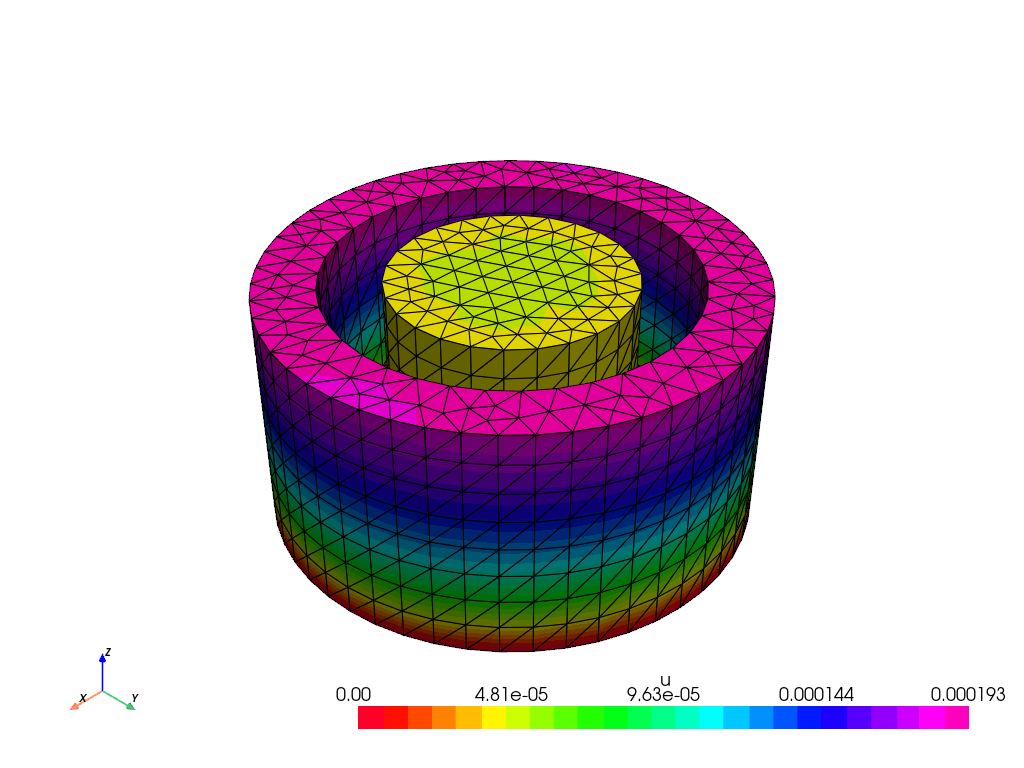

In [107]:
import pyvista
pyvista.start_xvfb(1.2) # 1.2 ?

# Create plotter and pyvista grid
p = pyvista.Plotter()
topology, cell_types, geometry = dolfinx.plot.vtk_mesh(problem.V)
grid = pyvista.UnstructuredGrid(topology, cell_types, geometry)

# Attach vector values to grid and warp grid by vector
grid["u"] = displacement.x.array.reshape((geometry.shape[0], 3))
# grid["u"] = displacement.x.array.reshape(-1, 3)

p.add_mesh(grid, style="wireframe", color="k") # style = "points"
warped = grid.warp_by_vector("u")
# warped = grid.warp_by_vector("u", factor=1)
p.add_mesh(warped, show_edges=True, cmap=mpl.colormaps.get_cmap("gist_rainbow").resampled(25), lighting=True)
p.show_axes()

if not pyvista.OFF_SCREEN:
   p.show()
else:
   figure_as_array = p.screenshot("deflection.png")

# Paraview file
# with io.XDMFFile(problem.domain.comm, "deformation.xdmf", "w") as xdmf:
#     xdmf.write_mesh(problem.domain)
#     displacement.name = "Deformation"
#     xdmf.write_function(displacement)

## Stress computation
As soon as the displacement is computed, we can compute various stress measures. We will compute the von Mises stress defined as $\sigma_m=\sqrt{\frac{3}{2}s:s}$ where $s$ is the deviatoric stress tensor $s(u)=\sigma(u)-\frac{1}{3}\mathrm{tr}(\sigma(u))I$.

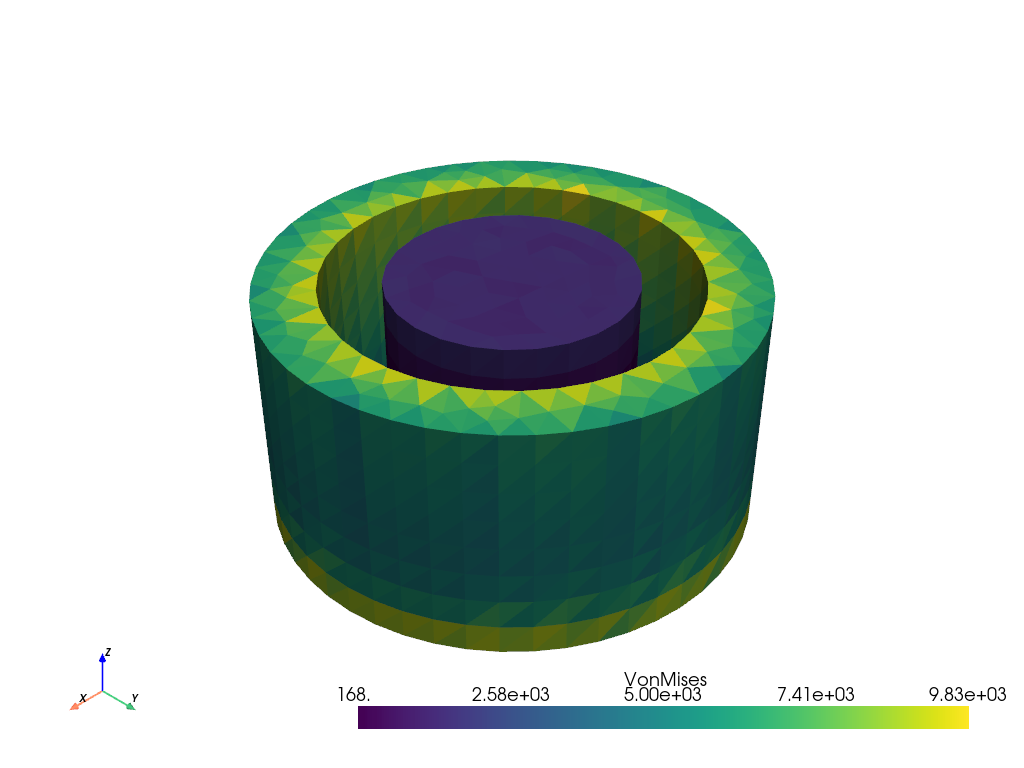

In [108]:
deviatoric_stress = stress_field - 1./3. * ufl.tr(stress_field) * ufl.Identity(len(problem.displacement))
von_Mises = ufl.sqrt(3./2*ufl.inner(deviatoric_stress, deviatoric_stress))

V_von_mises = dolfinx.fem.functionspace(problem.mesh, ("DG", 0))
stress_expr = dolfinx.fem.Expression(von_Mises, V_von_mises.element.interpolation_points())
stresses = dolfinx.fem.Function(V_von_mises)
stresses.interpolate(stress_expr)

warped.cell_data["VonMises"] = stresses.x.petsc_vec
warped.set_active_scalars("VonMises")
p = pyvista.Plotter()
p.add_mesh(warped)
p.show_axes()
if not pyvista.OFF_SCREEN:
   p.show()
else:
   stress_figure = p.screenshot(f"stresses.png")